# Introduction to Data Science 2026

# Week 5

## Exercise 1 | Privacy and data protection

First, look up the [European Data Protection Regulation](http://eur-lex.europa.eu/legal-content/EN/TXT/PDF/?uri=CELEX:32016R0679&from=en) (“GDPR”). Note that Articles 1-99 start on p. 32 of the document. We will refer to the articles and their parts by, e.g., “Art 6 (1) a) GDPR” which means Article 6 (“Lawfulness of processing”), first paragraph, item a in the GDPR.

1. Valid Consent?

    Find a service you use to which you have given *consent* for the processing of your personal data (Art 6 (1) a) GDPR). Have a look at the privacy notices, policies, or settings of this service.

    - Are the basic legal conditions for this consent in your opinion in line with the new requirements and conditions set by the GDPR?

    - You should provide an answer with justification based on the GDPR, where you refer to specific articles and paragraphs.

2. Your Right to Access your Personal Data

    You have the right to know if personal data about you is processed by a controller. You also have the right to get access to, for example, the processing purposes, the data categories, data transfers, and duration of storage.

    - Find the relevant parts in GDPR and study your rights as a “data subject”.

    - File a right-to-access request with a data processing service of your choosing. Describe the mechanism that is put in place by the service to enable you to exercise this right (if any).

    - Whether you get a response or not, think about how well your rights as a data subject are respected in practice. Your answer should again refer to specific articles and paragraphs of the GDPR.

3. Anonymisation & Pseudonymisation

    - What is the difference between anonymisation and pseudonymisation of personal data?

**Submit your findings in a PDF file, just a short report is enough.**

## Exercise 2 | Fairness-aware AI

This template generates data about the working hours and salaries of n=5000 people. The salary equals 100 x working hours plus/minus normal distributed noise. If you run the template, it produces an _hours_ vs _monthly salary_ scatter plot with gender=0 (men) in orange and gender=1 (women) in orange. The plot includes a trend line for each group, and an overall trend line for all data combined (in red). 

A linear regression model (see the next code cell) that only includes the working hours as a covariate *without* the protected characteristic (gender) should have slope close to 100.0.

In [2]:
%matplotlib inline
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression

### Simulating the data

In [3]:
#sample size n
n = 5000

# gender
gen = np.random.binomial(1, 0.5, size=n)

# work hours
hrs = np.random.binomial(60, 0.5, size=n)

# salary = 100 * hours + noise (std.deviation 10)
sal = hrs * np.random.normal(100, 10, size=n) 

# create a nice data frame
data = pd.DataFrame({"Gender": gen, "Hours": hrs, "Salary": sal})

### Scatterplot of the simulated data
Women samples (gender = 1) are shown with blue, men samples (gender = 0) are shown in orange.
Blue and orange lines are the trend lines of each group accordingly.
The overall trend line is shown in red.

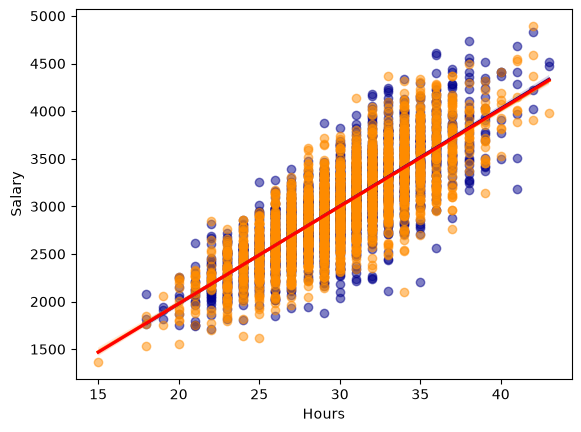

In [4]:
sns.regplot(x="Hours", y="Salary", data=data[data["Gender"]==1], color="darkBlue", scatter_kws={'alpha':0.5})

sns.regplot(x="Hours", y="Salary", data=data[data["Gender"]==0], color="darkOrange", scatter_kws={'alpha':0.5})

sns.regplot(x="Hours", y="Salary", data=data, marker="None", color="red")

plt.show()

### Linear regression
Learn the overall regression model, which is what an algorithm with no access to the gender ("protected characteristic") would learn from the data.

In [5]:
reg = LinearRegression().fit(hrs.reshape(-1,1), sal.reshape(-1,1))

# print out the slope: it should be close to 100.0 without learning the 'protected characteristic' (gender)
print("slope: %.1f" % reg.coef_[0][0])

slope: 102.1


### Task

Now edit the code to simulate each of the following scenarios:

a) the salary of women is reduced by 200 euros ("direct discrimination")

b) the working hours of men are binomially distributed with parameters (60, 0.55) while the working hours of women are binomially distributed with parameters (60, 0.45), no changes in per-hour salary ("no discrimination")

c) both of the above changes at the same time ("indirect discrimination")

You should be able to demonstrate that the slope of the linear regression model is only changed in one of these scenarios.

Based on this experiment, answer the following questions:
1. In which of the scenarios the slope (coefficient) of the regression model changes?
2. How could you model the data in a way that enables you to detect indirect discrimination? _Hint_: Should you include the protected characteristic in the model or not?

To answer the second question, demonstrate your solution by building a regression model and interpreting the estimated coefficients.

**Submit this exercise by submitting your code and your answers to the above questions on the MOOC platform. You can return this Jupyter notebook (.ipynb) or .py, .R, etc depending on your programming preferences.**

#### Solution

I wrap the simulation in one function so that the baseline and all three scenarious use identical code paths. A fixed random seed makes every result reproducible.

- Scenario a (direct discrimination): the salary of women (Gender = 1) os reduced by 200.
- Scenario b (no discrimination): men's hours are Binomial(60, 0.55), womem's hours Binomial(60, 0.45); per-hour salary is unchanged.
- Scenario c (indirect discrimination): both changes at the same time.

In [17]:
def simulate(scenario, n=5000, seed=2026):
    """Simulate the baseline ('base') or scenario 'a', 'b' or 'c'.

    A single shared seed is used for every scenario, so the gender draws and all
    random numbers are identical across scenarios and any difference in the results
    is attributable solely to the scenario mechanism itself.
    """
    rng = np.random.default_rng(seed)

    # gender: 0 = men, 1 = women
    gender = rng.binomial(1, 0.5, size=n)

    # working hours
    if scenario in ("b", "c"):
        hours = np.where(gender == 0,
                         rng.binomial(60, 0.55, size=n),   # men
                         rng.binomial(60, 0.45, size=n))   # women
    else:
        hours = rng.binomial(60, 0.5, size=n)

    # salary = hours * per-hour rate (mean 100, sd 10)
    salary = hours * rng.normal(100, 10, size=n)

    # scenarios a / c: a constant 200-euro cut for women
    if scenario in ("a", "c"):
        salary = salary - 200 * gender

    return pd.DataFrame({"Gender": gender, "Hours": hours, "Salary": salary})

scenarios = {s: simulate(s) for s in ("base", "a", "b", "c")}

# descriptive check: group means of hours and salary in each scenario
for name, df in scenarios.items():
    print(f"scenario {name:>4}: "
          f"mean hours  men={df.loc[df.Gender==0, 'Hours'].mean():5.2f}  "
          f"women={df.loc[df.Gender==1, 'Hours'].mean():5.2f} | "
          f"mean salary men={df.loc[df.Gender==0, 'Salary'].mean():8.1f}  "
          f"women={df.loc[df.Gender==1, 'Salary'].mean():8.1f}")

scenario base: mean hours  men=30.18  women=30.03 | mean salary men=  3017.1  women=  2997.2
scenario    a: mean hours  men=30.18  women=30.03 | mean salary men=  3017.1  women=  2797.2
scenario    b: mean hours  men=32.82  women=27.07 | mean salary men=  3281.5  women=  2716.3
scenario    c: mean hours  men=32.82  women=27.07 | mean salary men=  3281.5  women=  2516.3


#### Slopes of the gender-blind model

For each scenario, I fit the same model as the template, Salary ~ Hours, which has no access to the protected characteristic.

In [18]:
slopes = {}
for name, df in scenarios.items():
    reg = LinearRegression().fit(df[["Hours"]], df[["Salary"]])
    slopes[name] = reg.coef_[0, 0]
    print("scenario %4s: slope = %.1f" % (name, slopes[name]))

scenario base: slope = 99.8
scenario    a: slope = 100.3
scenario    b: slope = 98.1
scenario    c: slope = 110.5


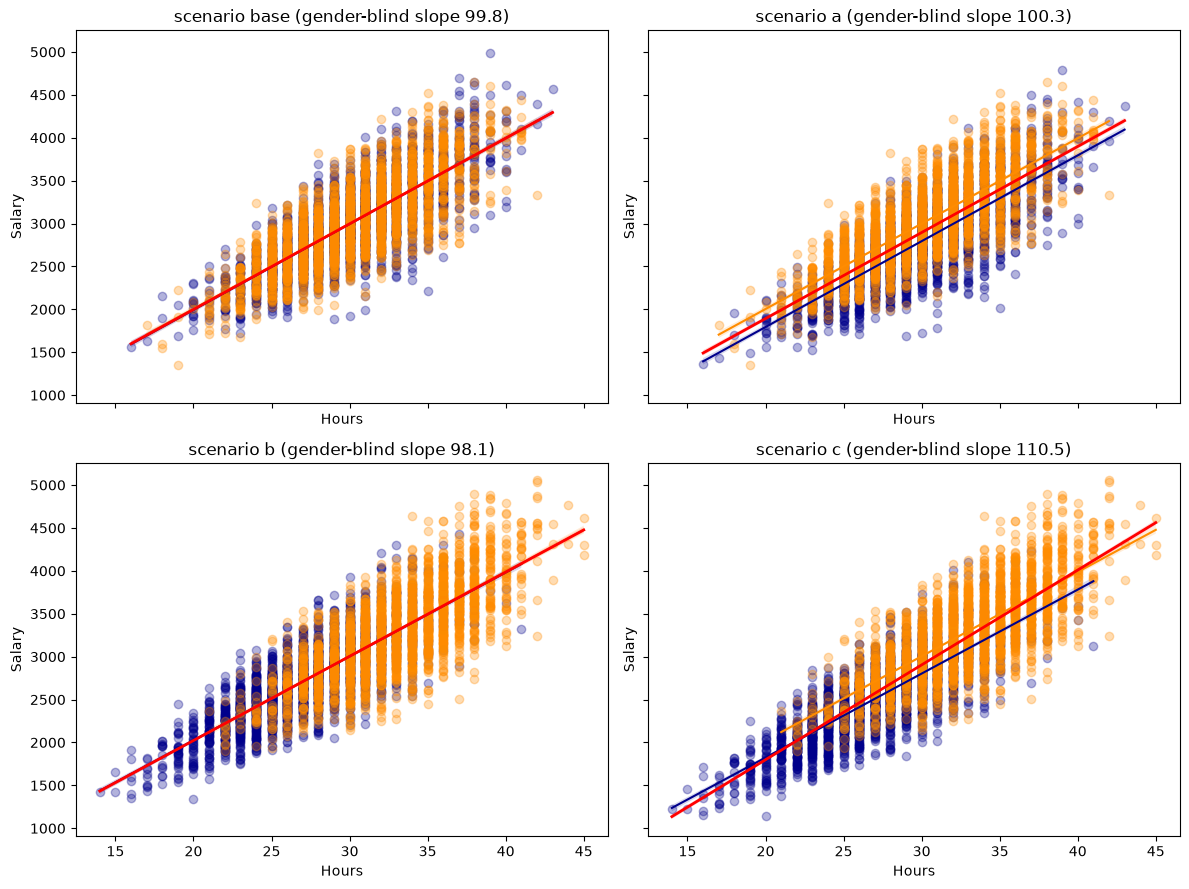

In [19]:
fig, axes = plt.subplots(2, 2, figsize=(12, 9), sharex=True, sharey=True)
for ax, (name, df) in zip(axes.ravel(), scenarios.items()):
    sns.regplot(x="Hours", y="Salary", data=df[df["Gender"] == 1],
                color="darkBlue", scatter_kws={"alpha": 0.3}, ax=ax,
                line_kws={"linewidth": 1.5})
    sns.regplot(x="Hours", y="Salary", data=df[df["Gender"] == 0],
                color="darkOrange", scatter_kws={"alpha": 0.3}, ax=ax,
                line_kws={"linewidth": 1.5})
    sns.regplot(x="Hours", y="Salary", data=df, marker="None",
                color="red", ax=ax, line_kws={"linewidth": 2})
    ax.set_title("scenario %s (gender-blind slope %.1f)" % (name, slopes[name]))
plt.tight_layout()
plt.show()

#### Model that includes the protected characteristic

To detect discrimination, I fit Salary ~ Hours + Gender, and additionally Hours ~ Gender to quantify how the protected characteristic shifts the covariate itself.

In [20]:
rows = []
for name, df in scenarios.items():
    # adjusted model: salary on hours AND gender
    m_adj = LinearRegression().fit(df[["Hours", "Gender"]], df["Salary"])
    hours_coef, gender_coef = m_adj.coef_

    # how many fewer/more hours does gender predict?
    m_hours = LinearRegression().fit(df[["Gender"]], df["Hours"])
    hours_gap = m_hours.coef_[0]

    observed_gap = (df.loc[df["Gender"] == 1, "Salary"].mean()
                    - df.loc[df["Gender"] == 0, "Salary"].mean())
    direct_effect = gender_coef
    indirect_effect = hours_coef * hours_gap

    rows.append({
        "Scenario": name,
        "Slope, Hours only": slopes[name],
        "Hours coef (adjusted)": hours_coef,
        "Gender coef (direct)": gender_coef,
        "Hours gap (W-M)": hours_gap,
        "Indirect effect": indirect_effect,
        "Observed salary gap (W-M)": observed_gap,
        "Direct + indirect": direct_effect + indirect_effect,
    })

results = pd.DataFrame(rows).set_index("Scenario").round(1)
results

,"Slope, Hours only",Hours coef (adjusted),Gender coef (direct),Hours gap (W-M),Indirect effect,Observed salary gap (W-M),Direct + indirect
Scenario,,,,,,,
base,99.8,99.8,-4.7,-0.2,-15.3,-19.9,-19.9
a,100.3,99.8,-204.7,-0.2,-15.3,-219.9,-219.9
b,98.1,98.0,-1.9,-5.7,-563.3,-565.3,-565.3
c,110.5,98.0,-201.9,-5.7,-563.3,-765.3,-765.3


#### Answers

1. In which scenario does the slop (coefficient) of the regression model change?

The slop changes only in scenario c, indirect discrimination. The gender-build slope stays close to 100 in the baseline and in scencarios a and b, but is inflated to about 111 in c.

- scenario a: the -200e is a constant shift that does not depend on hours, and both groups have same hours distribition. It moves onlys intercept. The marginal euro paid per hour is still about 100, so the slope is unchanged.
- scenario b: the two groups differ in their distribution of hours, but the conditional relationship is unchanged about 100/hr, so the slop is again unchange.
- scenario c: gender is corrected with both variables. When gender is imitted, the constant 200e penalty is explained by hours through the group difference in hours. This is classic omitted-variable bias. The single red trend line is steeper than either group-specific line even though nobody is paid more 100/hr. Formally, the distortion of the blind slope is 
$$\frac{\beta_{Gender} \text{Cov(Hours, Gender)}}{\text{Var(Hours)}},$$
which is zero in scenarios a and c.

2. How can the data be modelled to detect indirect discrimination?

Include the protected characteristic in the model, as an explanation step:

- Salary ~ Hours + Gender puts the hours slope back to about 100 in every scenario and gives a Gener coefficient about -200 in scenario a and c, which exposing the direct pay penaly that the gender-blind slope hide in c. In scenario b the Gender coefficient is about 0, correctly indicating equal pay per hour.
- Per-hour pay is not the whold story. Hours ~ Gender shows that in scneario a and c women work on average about 6 fewer hours, which at rougthly 100/hour corresponds to an indirect effect of about -600e/month.
- The observed average salary gap is therefore decomposed as

  | Scenario | Direct (Gender coef) | Indirect (via hours) | Observed gap |
  |---|---|---|---|
  | a | about −200 | about 0 | about −200 |
  | b | about 0 | about −600 | about −600 |
  | c | about −200 | about −600 | about −800 |
  
  in b the gap is entirely indirect. In c it combines a direct penalty with the hours-mediated component. The direct + indirect column in teh able above reproduces the observed gap, confirming the decomposition.
